In [40]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.simplefilter(action='ignore',category= UserWarning)

In [41]:
# Load dataset
df = pd.read_csv('wine.csv')

In [42]:
# Basic data exploration
print(df.head())
print(df.describe())
print(df.info())

   Type  Alcohol  Malic   Ash  Alcalinity  Magnesium  Phenols  Flavanoids  \
0     1    14.23   1.71  2.43        15.6        127     2.80        3.06   
1     1    13.20   1.78  2.14        11.2        100     2.65        2.76   
2     1    13.16   2.36  2.67        18.6        101     2.80        3.24   
3     1    14.37   1.95  2.50        16.8        113     3.85        3.49   
4     1    13.24   2.59  2.87        21.0        118     2.80        2.69   

   Nonflavanoids  Proanthocyanins  Color   Hue  Dilution  Proline  
0           0.28             2.29   5.64  1.04      3.92     1065  
1           0.26             1.28   4.38  1.05      3.40     1050  
2           0.30             2.81   5.68  1.03      3.17     1185  
3           0.24             2.18   7.80  0.86      3.45     1480  
4           0.39             1.82   4.32  1.04      2.93      735  
             Type     Alcohol       Malic         Ash  Alcalinity   Magnesium  \
count  178.000000  178.000000  178.000000  178.0

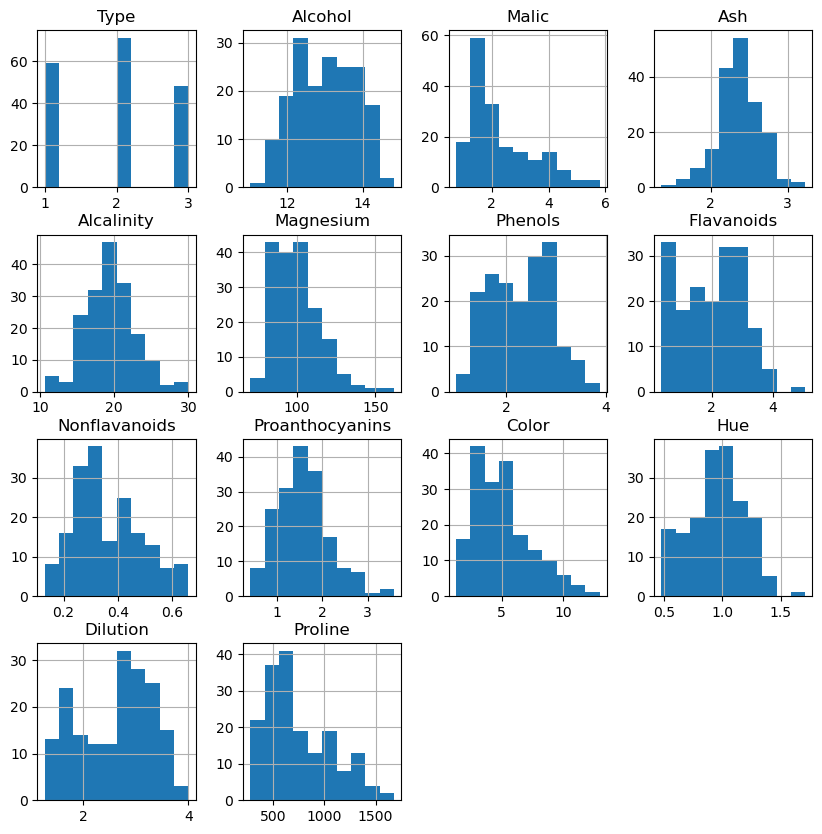

In [43]:
# Histograms
df.hist(figsize=(10, 10))
plt.show()

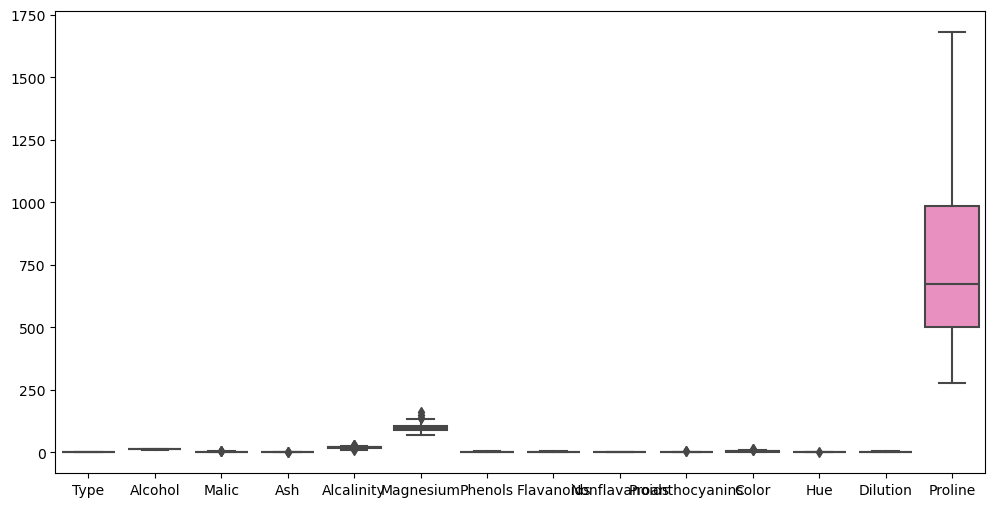

In [44]:
# Boxplots
plt.figure(figsize=(12, 6))
sns.boxplot(data=df)
plt.show()

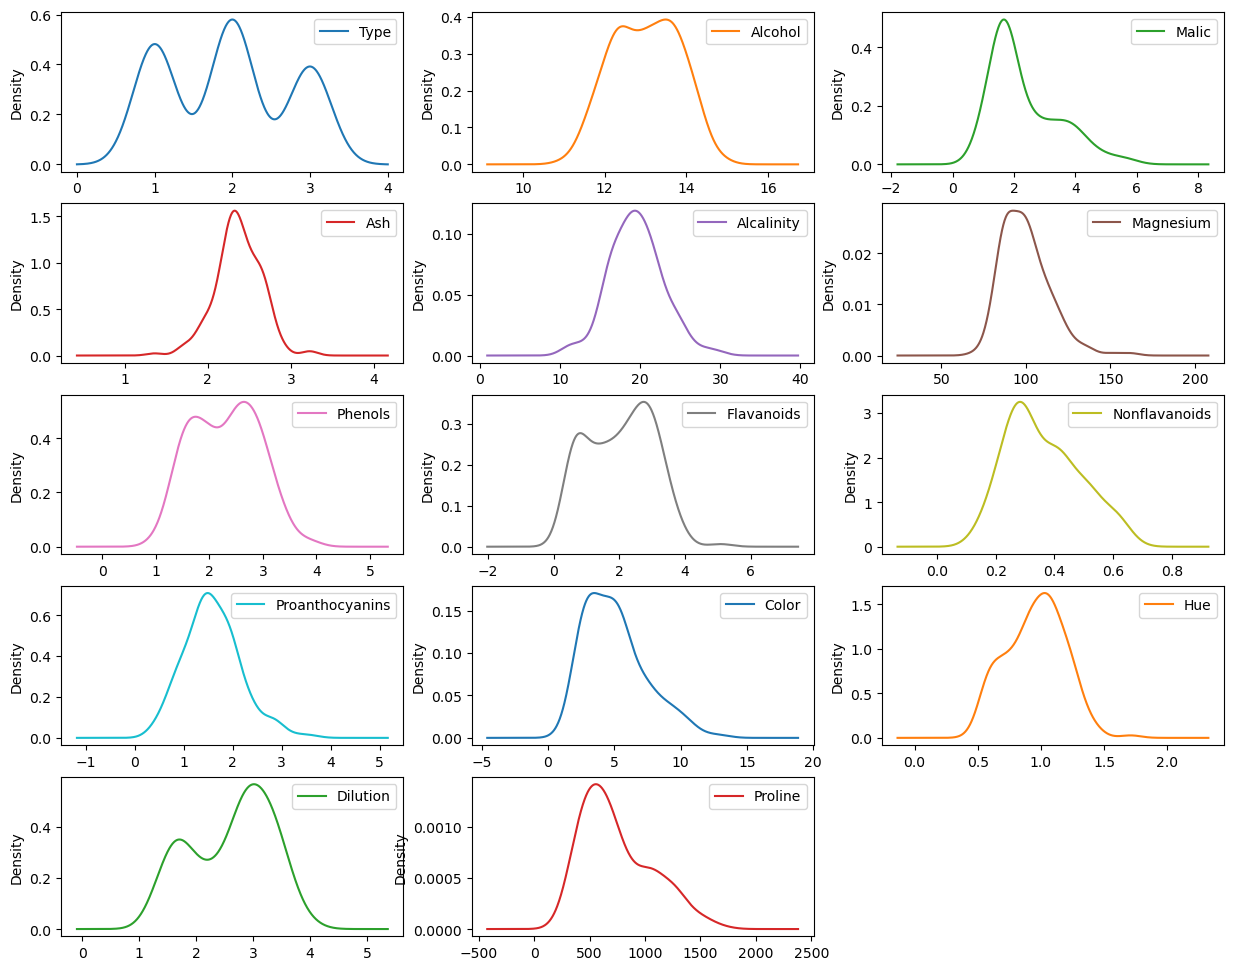

In [45]:
# Density plots
df.plot(kind='density', subplots=True, layout=(5, 3), sharex=False, figsize=(15, 12))
plt.show()

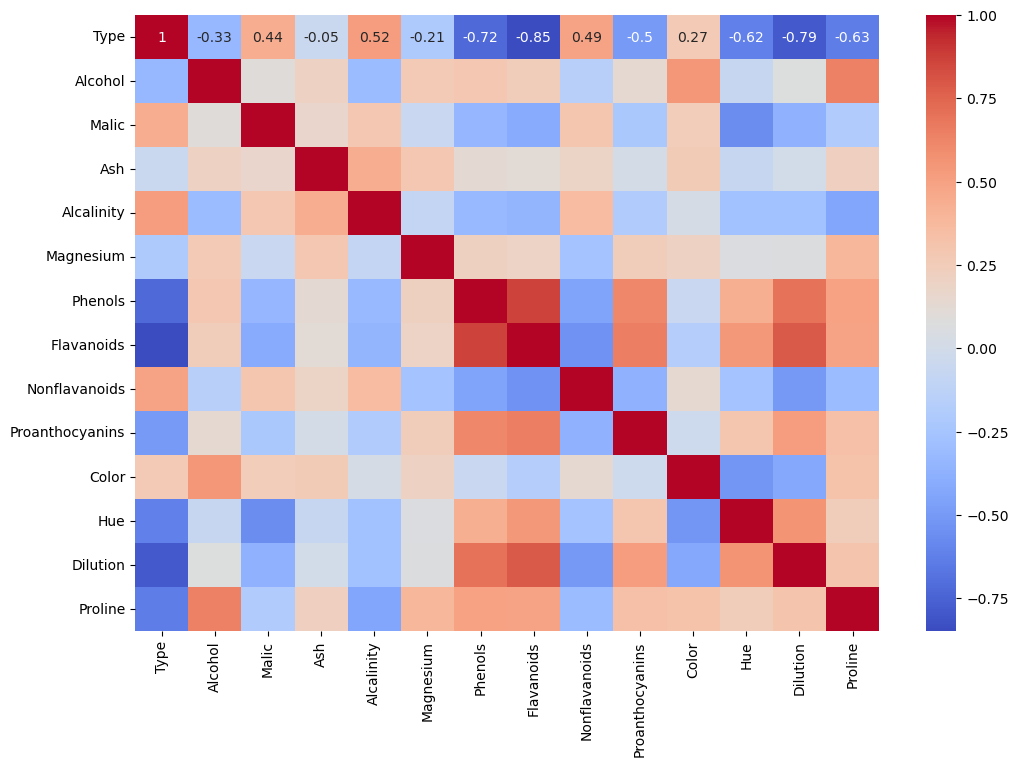

In [46]:
# Correlation matrix
corr_matrix = df.corr()
plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm')
plt.show()

In [47]:
from sklearn.preprocessing import StandardScaler
# Standardize the data
scaler = StandardScaler()
df_scaled = scaler.fit_transform(df)

In [48]:
from sklearn.decomposition import PCA
# Apply PCA
pca = PCA()
pca.fit(df_scaled)

PCA()

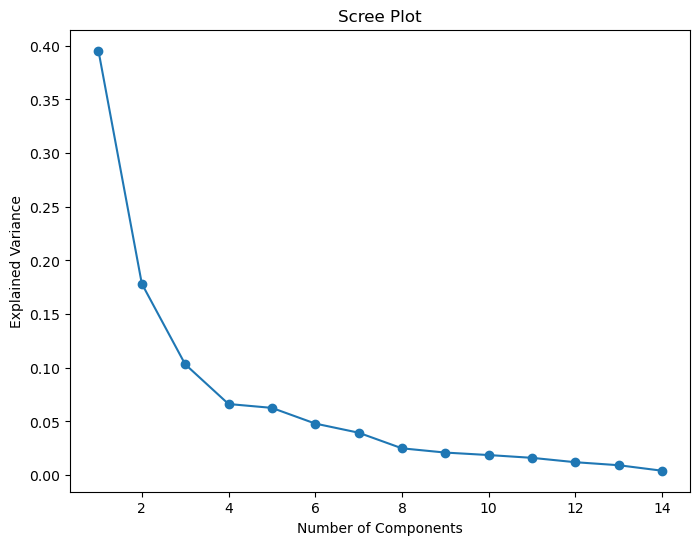

In [49]:
# Scree plot
plt.figure(figsize=(8, 6))
plt.plot(range(1, len(pca.explained_variance_ratio_) + 1), pca.explained_variance_ratio_, marker='o')
plt.title('Scree Plot')
plt.xlabel('Number of Components')
plt.ylabel('Explained Variance')
plt.show()

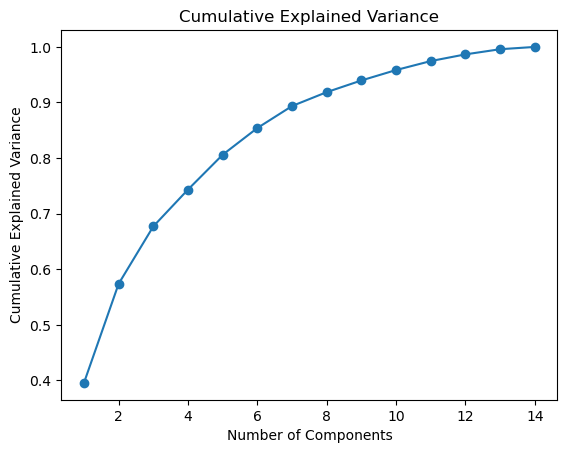

In [50]:
# Cumulative explained variance
cumulative_variance = pca.explained_variance_ratio_.cumsum()
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker='o')
plt.title('Cumulative Explained Variance')
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.show()

In [51]:
from sklearn.decomposition import PCA
# Initialize PCA without specifying the number of components
pca = PCA()
# Fit PCA to the scaled data
pca.fit(df_scaled)

PCA()

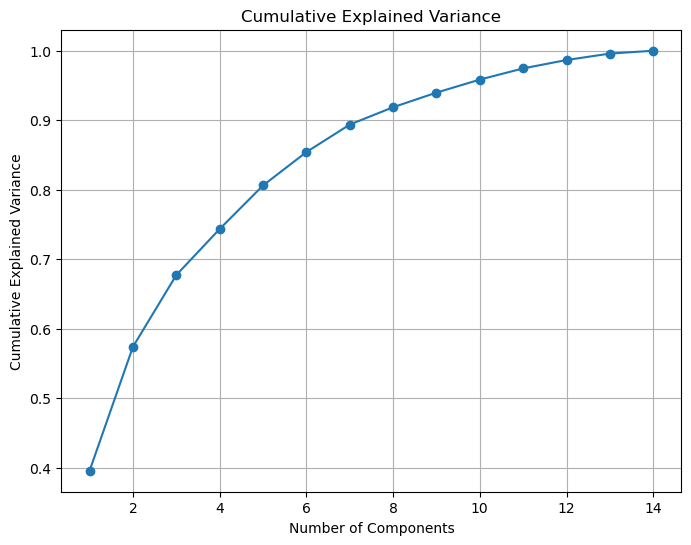

In [52]:
# Calculate cumulative explained variance
cumulative_variance = pca.explained_variance_ratio_.cumsum()
# Plot cumulative explained variance to visually determine the optimal number of components
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 6))
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker='o')
plt.title('Cumulative Explained Variance')
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.grid(True)
plt.show()

In [53]:
# Set a threshold for explained variance (e.g., 95%)
variance_threshold = 0.95
# Find the number of components that explain 95% of the variance
optimal_components = next(i for i, cumulative_var in enumerate(cumulative_variance) if cumulative_var >= variance_threshold) + 1
print(f'Optimal number of components: {optimal_components}')

Optimal number of components: 10


In [54]:
# Now apply PCA with the optimal number of components
pca = PCA(n_components=optimal_components)
# Transform the scaled data to the reduced dimension
df_pca = pca.fit_transform(df_scaled)
print(df_pca.shape) # Check the shape of the transformed data

(178, 10)


In [55]:
from sklearn.cluster import KMeans
# Apply K-Means
kmeans = KMeans(n_clusters=3) # Choose optimal k based on analysis
kmeans.fit(df_scaled)
labels = kmeans.labels_

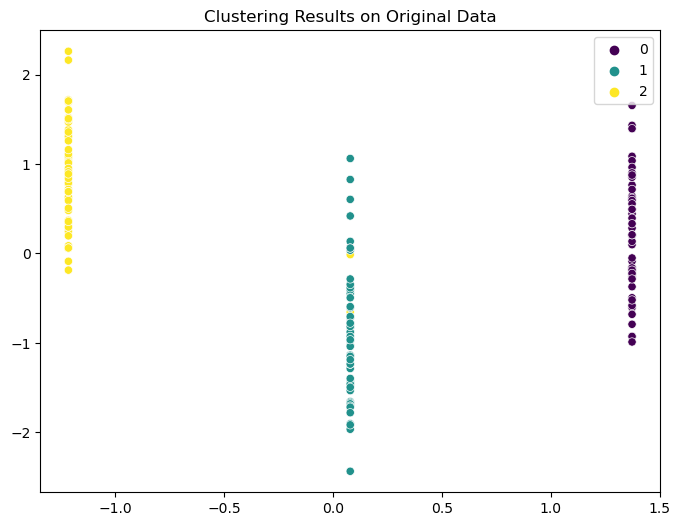

In [56]:
plt.figure(figsize=(8, 6))
sns.scatterplot(x=df_scaled[:, 0], y=df_scaled[:, 1], hue=labels, palette='viridis')
plt.title('Clustering Results on Original Data')
plt.show()

In [57]:
from sklearn.metrics import silhouette_score, davies_bouldin_score
# Silhouette score
silhouette_avg = silhouette_score(df_scaled, labels)
print(f'Silhouette Score: {silhouette_avg}')

Silhouette Score: 0.30773604383565206


In [58]:
# Davies-Bouldin index
db_index = davies_bouldin_score(df_scaled, labels)
print(f'Davies-Bouldin Index: {db_index}')

Davies-Bouldin Index: 1.3163957434114109


In [59]:
kmeans_pca = KMeans(n_clusters=3)
kmeans_pca.fit(df_pca)
labels_pca = kmeans_pca.labels_

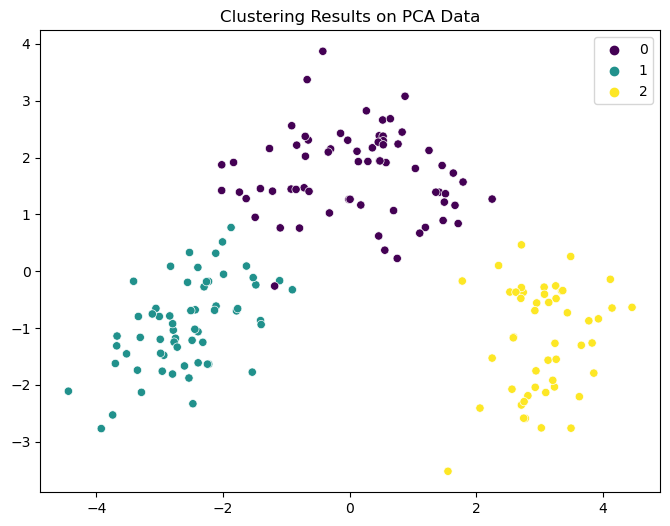

In [60]:
plt.figure(figsize=(8, 6))
sns.scatterplot(x=df_pca[:, 0], y=df_pca[:, 1], hue=labels_pca, palette='viridis')
plt.title('Clustering Results on PCA Data')
plt.show()

In [61]:
silhouette_avg_pca = silhouette_score(df_pca, labels_pca)
db_index_pca = davies_bouldin_score(df_pca, labels_pca)
print(f'Silhouette Score (PCA): {silhouette_avg_pca}')
print(f'Davies-Bouldin Index (PCA): {db_index_pca}')

Silhouette Score (PCA): 0.324065820533119
Davies-Bouldin Index (PCA): 1.2584890242254965


In [62]:
print(f'Original Data - Silhouette Score: {silhouette_avg}, DB Index: {db_index}')
print(f'PCA Data - Silhouette Score: {silhouette_avg_pca}, DB Index: {db_index_pca}')

Original Data - Silhouette Score: 0.30773604383565206, DB Index: 1.3163957434114109
PCA Data - Silhouette Score: 0.324065820533119, DB Index: 1.2584890242254965


In [ ]:
#Key Findings and Insights:
#Clustering on Original Data: The clustering algorithm (e.g., K-Means) applied to the original dataset produced a Silhouette Score of 0.3077 and a Davies-Bouldin Index (DBI) of 1.3164. The silhouette score indicates moderate separation between clusters, but the DBI suggests that there may still be some overlap or similarity between clusters.
#Clustering on PCA-Transformed Data: After applying PCA and reducing the dataset to fewer dimensions, the Silhouette Score improved to 0.3241 and the Davies-Bouldin Index decreased to 1.2585. These results show a slight improvement in both clustering quality and compactness, suggesting that dimensionality reduction through PCA had a positive effect on the clustering performance.

In [ ]:
#2. Practical Implications of Using PCA and Clustering:
#Dimensionality Reduction: PCA is useful when dealing with high-dimensional data, especially if there are many features that are correlated or redundant. By reducing the number of features, it helps to simplify the dataset, making it more computationally efficient to analyze and reducing noise that might interfere with clustering algorithms.
#Clustering Performance: PCA helped improve the performance of clustering, as shown by the better silhouette score and Davies-Bouldin index. In practical applications, using PCA can reveal hidden patterns in the data and allow clustering algorithms to perform more effectively by focusing on the most relevant features.
#Efficiency: PCA can make clustering faster, particularly on large datasets with many features, by reducing the computational complexity. This is especially important for real-time or large-scale data analysis.

In [ ]:
#3. Recommendations:
#When to Use PCA:
#Use PCA when the dataset has a large number of features, especially if there is significant multicollinearity (i.e., many features are correlated).
#Apply PCA if clustering results on the original dataset are suboptimal or computationally expensive.
#PCA is also recommended when you want to visualize high-dimensional data in 2D or 3D for exploratory analysis.
#When to Use Clustering Directly on Original Data:
#If the dataset is already low-dimensional or if the features are not highly correlated, clustering directly on the original dataset may provide good results.
#If interpretability of the features is important, clustering without PCA may help preserve the original structure and meaning of the features.
#For small datasets, where computational efficiency is not a concern, clustering on the original data might be sufficient.
#Trade-offs: Using PCA reduces the number of features and can improve clustering performance, but it may also make the results harder to interpret, as the principal components are linear combinations of the original features. It's important to balance dimensionality reduction with the need for interpretability, depending on the specific use case.